# 2. Plots, fits and means

Continues notebook 1. Same project, plus a second data set: `data/lowpass.csv`, the gain of an RC
low-pass over frequency.

In [1]:
import numpy as np

from pemlab import FitStyle, LayoutStyle, NumberStyle, PointStyle, Project

lab = Project("pemlab_build", tex_prefix="pemlab_build")

U, I, SIGMA_U = "U [V]", "I [A]", r"$\sigma_U$ [V]"
R, SIGMA_R = r"$R$ [\Omega]", r"$\sigma_R$ [\Omega]"

resistor = lab.edit_csv("data/resistor.csv", name="resistor")
resistor.replace_column("I [mA]", I, "I_mA * 1e-3", I_mA="I [mA]", show=False)
resistor.add_uncertainty(SIGMA_U, "U", {"U": 0.01}, U=U)
resistor.add_column(R, "U / I", U=U, I=I, numbers=NumberStyle(decimals=1), show=True)
resistor.add_uncertainty(SIGMA_R, "U / I", {"U": SIGMA_U, "I": 2e-5}, U=U, I=I,
                         numbers=NumberStyle(decimals=1), show=True)

,U [V],I [A],$\sigma_U$ [V],$R$ [\Omega],$\sigma_R$ [\Omega]
0,0.943,0.002,0.01,471.500000,6.872498
1,1.870,0.004,0.01,467.500000,3.422558
2,2.828,0.006,0.01,471.333333,2.290451
3,3.769,0.008,0.01,471.125000,1.717481
4,4.680,0.010,0.01,468.000000,1.369707
5,5.627,0.012,0.01,468.916667,1.142467
6,6.581,0.014,0.01,470.071429,0.980386
7,7.517,0.016,0.01,469.812500,0.857616
8,8.460,0.018,0.01,470.000000,0.762468
9,9.391,0.020,0.01,469.550000,0.685913


## Select the data

`lab.analysis` creates an analysis for a table. `make_PlotData` selects columns by their full name:
x, y and optionally the uncertainty of y.

In [2]:
analysis = lab.analysis(resistor)
data = analysis.make_PlotData(I, U, SIGMA_U)

## Plot the points

The first argument is the name of the plot. It names the folder and files in the build folder.

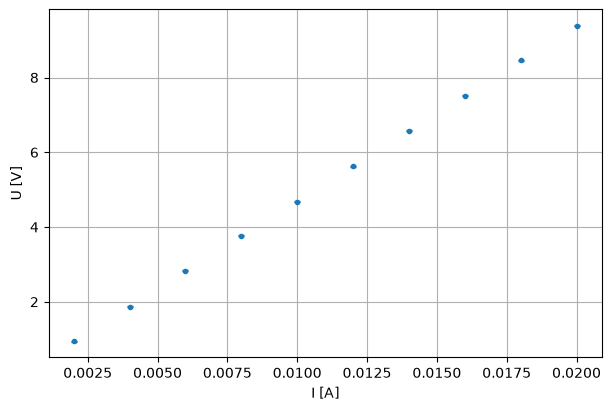

In [3]:
analysis.plot_data("resistor_data", data)

## Fit a function

The first argument of the function is `x`, the others are the fit parameters. Write the function
as a single `return` line so pemlab can show the formula. The result has the parameters with
uncertainties and $\chi^2$ per degree of freedom.

In [4]:
def ohm(x, R):
    return R * x


result = analysis.regression("ohms_law", ohm, data)

R = 469.69 ± 0.25
chi²/ndf = 7.62/9 = 0.847


In [5]:
result

FitResult(R=470)

## Change the look

Three style objects, every field has a default, you only name what you change:

- `PointStyle`: marker, size, color, connecting line, legend text
- `FitStyle`: color, line width and style of the fit curve
- `LayoutStyle`: figure size, labels, log axes, limits, grid, legend, font size

They can be passed to one plot (`points=`, `fit=`, `layout=`).

In [6]:
analysis.regression(
    "ohms_law_styled", ohm, data,
    points=PointStyle(marker="s", marker_size=4, label="measured"),
    fit=FitStyle(color="crimson", linestyle="--"),
    layout=LayoutStyle(figsize=(5, 3.5), xlabel="current $I$ [A]", title="Ohm's law", font_size=9),
)

R = 469.69 ± 0.25
chi²/ndf = 7.62/9 = 0.847


FitResult(R=470)

## Mean of a series

`mean` gives the mean with standard deviation and the uncertainty of the mean. `reference` adds
the deviation from a known value (here 470 $\Omega$). With `sigma`, the weighted mean is used and
the reduced $\chi^2$ shows whether the values agree within their uncertainties.

In [7]:
analysis.mean("resistance_mean", R, reference=470)
analysis.mean("resistance_weighted", R, sigma=SIGMA_R, reference=470)

n = 10
mean = 469.78 ± 0.43
standard deviation = 1.35
deviation from 470 = -0.219, -0.047 %, 0.51 sigma
n = 10
weighted mean = 469.68 ± 0.35
standard deviation = 1.35
chi²/ndf = 0.45
deviation from 470 = -0.315, -0.067 %, 0.9 sigma


MeanResult(n=10, mean=469.684726377033, std=1.353172928884596, error=0.3496210331765906, weighted=True, chi2_ndf=0.45008078039753957, reference=470)

## A nonlinear fit

Columns without a unit are allowed, a gain $H = U_\mathrm{out}/U_\mathrm{in}$ is dimensionless.
For nonlinear functions, start values `p0` help.

In [8]:
F, H, SIGMA_H = "f [Hz]", "H", r"$\sigma_H$"

lowpass = lab.edit_csv("data/lowpass.csv", name="lowpass")
lowpass.add_column(H, "U_out / U_in", U_out="U_out [V]", U_in="U_in [V]",
                   numbers=NumberStyle(decimals=4), show=True)
lowpass.add_uncertainty(SIGMA_H, "U_out / U_in", {"U_out": "sigma_U_out [V]", "U_in": 0.01},
                        U_out="U_out [V]", U_in="U_in [V]", numbers=NumberStyle(decimals=4),
                        show=True)


def lowpass_model(x, f_g):
    return 1 / np.sqrt(1 + (x / f_g) ** 2)


low = lab.analysis(lowpass)
low_data = low.make_PlotData(F, H, SIGMA_H)
low.regression("lowpass_gain", lowpass_model, low_data, p0=[1500],
               layout=LayoutStyle(xscale="log"))

f_g = 1591 ± 12
chi²/ndf = 3.45/10 = 0.345


FitResult(f_g=1.59e+03)

## Build

`build` writes everything to the build folder (deleting it first). One folder per table, plot and
mean; each plot comes as a single LaTeX float with figure, caption, fit result and the
calculations that were used.

In [9]:
lab.build()

from pathlib import Path

print((Path("pemlab_build") / "plots" / "ohms_law" / "ohms_law.tex").read_text(encoding="utf-8"))

\begin{figure}[H]
  \centering
  \includegraphics[width=0.8\textwidth]{pemlab_build/plots/ohms_law/ohms_law.pdf}
  \caption{U [V] vs. I [A]}
  \label{fig:ohms_law}
  \par\medskip
  {\footnotesize
Regression: $U = R \cdot I$
\par\smallskip
\begin{tabular}{lrr}
  parameter & value & error \\
  \hline
  $R$ & \num{469.69} & $\pm$ \num{0.25} \\
\end{tabular}
\par\smallskip
$\chi^2/\mathrm{ndf} = 7.62/9 = 0.847$
  }
\end{figure}



## In your report

```latex
\input{pemlab_build/plots/ohms_law/ohms_law}
\input{pemlab_build/means/resistance_mean/resistance_mean}
\input{pemlab_build/plots/lowpass_gain/lowpass_gain}
```

Next: measuring with instruments (notebook 3).